# 05 - Manual overrides, streak diagnosis and strict QC

* 07: hand overrides of 4 nuclei clusters (`07_clean/nuclei_overrides.tsv`: 4 -> Hepatocyte flagged possible doublet,
  76 -> Cholangiocyte, 0 and 62 -> unresolved).
* 09: why the UMAP still had streaks after the clean-up (needs the clean TotalVI latent, heavy notebook 12; record linked).
* 10: strict QC approximating the authors' "strict QC controls eliminating these potential doublets" (Cell 2022 p.382):
  per-cell scDblFinder doublets, < 200 UMI after decontX, between-type (bridge) cells, FACS sort-gate mismatches.

Result of record: 234,552 kept (sort mismatch 39,843; scDblFinder 35,042; < 200 UMI 8,522; bridge 3,100).

**Runtime:** ~20 min
**Envs used (each step runs as a subprocess in its own env):** rapids-sc
**Kernel:** `masld_atlas` (orchestration only).

Outputs are written under `/mnt/masld_vault/cross_species_repro/` (mirror of `/mnt/masld_vault/cross_species/`, the outputs
of record). Inputs this notebook does not rebuild are linked from the record; see `repro_setup.py` for the safety rules.

In [1]:
%run -i /home/ubuntu/liver_cross_species/notebooks/repro_setup.py
print("RECORD", RECORD); print("REPRO ", REPRO); print("WORK  ", WORK)

RECORD /mnt/masld_vault/cross_species
REPRO  /mnt/masld_vault/cross_species_repro
WORK   /home/ubuntu/liver_cross_species/notebooks/work


### 07 - overrides (rewrites the 07_clean files in place, so it needs notebook 04's rebuilt 07_clean)

In [2]:
import shutil
if is_real("guilliams2022/07_clean"):
    shutil.copy2(rec("guilliams2022/07_clean/nuclei_overrides.tsv"), rep("guilliams2022/07_clean/nuclei_overrides.tsv"))
    print(open(rep("guilliams2022/07_clean/nuclei_overrides.tsv")).read())
    DO_07 = True
else:
    link("guilliams2022/07_clean"); DO_07 = False
    print("07_clean not rebuilt (run notebook 04 first): the record's 07_clean already carries the overrides; step 07 skipped")

# Manual cluster overrides (TotalVI draft Leiden r3), user decision 2026-11-11. Applied to the whole cluster.
# Evidence = mean log-normalised marker expression in the nuclei of the cluster (07_clean, cleaned counts).
leiden_totalvi_r3	annotation_clean	annotation_curated	flag	evidence
4	Endothelial	Hepatocyte	possible_doublet_hep_LSEC	Alb 3.16 Cyp2e1 1.72 Cyp2f2 0.94 with Stab2 1.53 Kdr 0.45; 95% nuclei
76	HsPCs	Cholangiocyte		Krt19 0.88 Spp1 0.52, no Kit/Cd34; 100% nuclei
0	Fibroblast	unresolved	check_after_reintegration	Alb 2.71 with Reln 1.62 Dcn 0.88; 92% nuclei
62	Neutrophil	unresolved	check_after_reintegration	no S100a8/Retnlg; Dcn 0.95 Krt19 0.34; 57% nuclei



In [3]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/07_apply_overrides.py
"""Step 07 - apply the manual cluster overrides (07_clean/nuclei_overrides.tsv) to the three clean files.
Adds obs annotation_curated (= annotation_clean unless overridden) and annotation_flag; rewrites the files in place (tmp + rename)."""
import os

import anndata as ad
import pandas as pd

D = "/mnt/masld_vault/cross_species_repro/guilliams2022/07_clean"
ov = pd.read_csv(f"{D}/nuclei_overrides.tsv", sep="\t", comment="#", dtype=str).fillna("")
ov = ov.set_index("leiden_totalvi_r3")
rows = []
for f in ("guilliams2022_fig1b_clean.h5ad", "guilliams2022_fig1b_clean_cells.h5ad", "guilliams2022_fig1b_clean_nuclei.h5ad"):
    a = ad.read_h5ad(f"{D}/{f}")
    cl = a.obs["leiden_totalvi_r3"].astype(str)
    cur = a.obs["annotation_clean"].astype(str).copy()
    flag = pd.Series("", index=a.obs_names)
    hit = cl.isin(ov.index)
    cur[hit] = ov.loc[cl[hit], "annotation_curated"].values
    flag[hit] = ov.loc[cl[hit], "flag"].values
    a.obs["annotation_curated"] = pd.Categorical(cur)
    a.obs["annotation_flag"] = pd.Categorical(flag)
    a.uns["annotation_overrides"] = "07_clean/nuclei_overrides.tsv (user decision 2026-11-11), applied per TotalVI draft Leiden r3 cluster"
    a.write_h5ad(f"{D}/{f}.tmp", compression="gzip")
    os.replace(f"{D}/{f}.tmp", f"{D}/{f}")
    t = a.obs.groupby(["annotation_curated", "suspension"], observed=True).size().unstack(fill_value=0)
    print(f, a.shape, "overridden", int(hit.sum()), flush=True)
    if f.endswith("clean.h5ad"):
        t["total"] = t.sum(1)
        t.sort_values("total", ascending=False).to_csv(f"{D}/composition_curated.tsv", sep="\t")
        print(t.sort_values("total", ascending=False).to_string(), flush=True)

Writing /home/ubuntu/liver_cross_species/notebooks/work/07_apply_overrides.py


In [4]:
if DO_07: run("07_apply_overrides.py", "rapids-sc")

guilliams2022_fig1b_clean.h5ad (321059, 31053) overridden 10010
suspension           cell  nucleus  total
annotation_curated
Endothelial         75970     2861  78831
Hepatocyte          60209    18149  78358
KC                  57316      967  58283
Monocyte            21530       30  21560
T cell              15621      128  15749
pDCs                12970        9  12979
B cell               9719      128   9847
cDC2                 9105       80   9185
cDC1                 7875       30   7905
Fibroblast           3581     2778   6359
ILC1                 5407        9   5416
unresolved            748     4134   4882
Neutrophil           4558        2   4560
Cholangiocyte        1488     1393   2881
NK cell              2516        6   2522
Mig. cDCs            1061        3   1064
Basophil              677        1    678
guilliams2022_fig1b_clean_cells.h5ad (290351, 31053) overridden 990
guilliams2022_fig1b_clean_nuclei.h5ad (30708, 31053) overridden 9020
--- 07_apply_overrides.p

### 09 - streak diagnostic

In [5]:
link("guilliams2022/08_totalvi_clean")   # clean TotalVI latent (heavy notebook 12) from the record unless rebuilt
fresh("guilliams2022/08_totalvi_clean/streaks")

linked    guilliams2022/08_totalvi_clean  (record)
output    guilliams2022/08_totalvi_clean/streaks


In [6]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/09_streak_diagnostic.py
"""Step 09 - why streaks? Per cell: bridge score = fraction of 15 nearest neighbours (TotalVI clean latent) in a different
Leiden r1 cluster. Cross-tab against scDblFinder, low UMI, decontX lt200, CS140, suspension. Then re-draw UMAP after removing
(a) per-cell scDblFinder doublets, (b) + bridge cells (score > 0.5) - an approximation of the authors' strict QC.
Output 08_totalvi_clean/streaks/: tables + figures."""
import anndata as ad
import matplotlib
import numpy as np
import pandas as pd
import rapids_singlecell as rsc
import scanpy as sc

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from cuml.neighbors import NearestNeighbors

D = "/mnt/masld_vault/cross_species_repro/guilliams2022/08_totalvi_clean"
O = f"{D}/streaks"
import os
os.makedirs(O, exist_ok=True)
E = ad.read_h5ad(f"{D}/embeddings.h5ad")
Z = E.obsm["X_totalvi"].astype(np.float32)
nn = NearestNeighbors(n_neighbors=16).fit(Z)
_, idx = nn.kneighbors(Z)
idx = np.asarray(idx)[:, 1:]
cl = E.obs["leiden_clean_r1"].astype(str).values
E.obs["bridge"] = (cl[idx] != cl[:, None]).mean(1)
o = E.obs
o["low_umi"] = o["umis_final"] < 1000
o["bridge_cell"] = o["bridge"] > 0.5
flags = ["scDblFinder_doublet", "dx_lt200", "low_umi", "ambient_dominated"]
rows = []
for f in flags + ["bridge_cell"]:
    v = o[f].astype(bool)
    rows.append(dict(flag=f, n=int(v.sum()), pct_all=v.mean() * 100,
                     pct_among_bridge=v[o.bridge_cell].mean() * 100, pct_among_nonbridge=v[~o.bridge_cell].mean() * 100))
t = pd.DataFrame(rows)
t.to_csv(f"{O}/flags_vs_bridge.tsv", sep="\t", index=False, float_format="%.2f")
print(t.to_string(index=False, float_format=lambda x: f"{x:.1f}"))
print("bridge score by scDblFinder class:\n", o.groupby("scDblFinder_doublet").bridge.describe().round(3))
print("bridge by suspension:\n", o.groupby("suspension", observed=True).bridge_cell.mean().round(3))

U = E.obsm["X_umap_totalvi"]
fig, axs = plt.subplots(1, 4, figsize=(28, 7))
for ax, (v, ttl, cm) in zip(axs, [(o.bridge.values, "bridge score (frac. neighbours in other cluster)", "magma"),
                                  (o.scDblFinder_doublet.values.astype(float), "scDblFinder doublet (per cell)", "Reds"),
                                  (np.log10(o.umis_final.values + 1), "log10 UMI (cleaned)", "viridis"),
                                  (o.decontX_contamination_final.fillna(0).values, "decontX contamination (tier-1 samples)", "magma")]):
    r = np.argsort(v)
    s = ax.scatter(U[r, 0], U[r, 1], c=v[r], s=0.2, cmap=cm, rasterized=True)
    ax.set_title(ttl); ax.axis("off"); fig.colorbar(s, ax=ax, shrink=0.6)
fig.savefig(f"{O}/umap_streak_drivers.png", dpi=150, bbox_inches="tight")

def redraw(mask, tag):
    g = ad.AnnData(obs=o.loc[mask, ["annotation_curated"]].copy(), obsm={"Z": Z[mask]})
    rsc.pp.neighbors(g, use_rep="Z")
    rsc.tl.umap(g, random_state=0)
    return g

ga = redraw(~o.scDblFinder_doublet.values, "a")
gb = redraw(~(o.scDblFinder_doublet.values | o.bridge_cell.values | o.dx_lt200.values), "b")
fig, axs = plt.subplots(1, 3, figsize=(30, 9))
full = ad.AnnData(obs=o[["annotation_curated"]].copy(), obsm={"X_umap": U})
for ax, (g, ttl) in zip(axs, [(full, f"all clean cells ({len(o):,})"), (ga, f"- scDblFinder doublets ({ga.n_obs:,})"),
                              (gb, f"- doublets, bridge cells, <200 UMI after decontX ({gb.n_obs:,})")]):
    sc.pl.umap(g, color="annotation_curated", ax=ax, show=False, frameon=False, s=1, legend_loc="on data",
               legend_fontsize=6, title=ttl)
    for c in ax.collections:
        c.set_rasterized(True)
fig.savefig(f"{O}/umap_strict_qc_approx.png", dpi=150, bbox_inches="tight")
fig.savefig(f"{O}/umap_strict_qc_approx.pdf", dpi=300, bbox_inches="tight")
print("cells after a:", ga.n_obs, "after b:", gb.n_obs)
comp = pd.concat([o.annotation_curated.value_counts().rename("clean"),
                  gb.obs.annotation_curated.value_counts().rename("strict_approx")], axis=1)
comp.to_csv(f"{O}/composition_strict_approx.tsv", sep="\t")
print(comp.to_string())

Writing /home/ubuntu/liver_cross_species/notebooks/work/09_streak_diagnostic.py


In [7]:
run("09_streak_diagnostic.py", "rapids-sc", gpu=0)

bridge by suspension:
 suspension
cell       0.015
nucleus    0.027
Name: bridge_cell, dtype: float64
cells after a: 286017 after b: 273593
                    clean  strict_approx
annotation_curated
Endothelial         78831          68002
Hepatocyte          78358          63251
KC                  58283          48112
Monocyte            21560          18455
T cell              15749          14902
pDCs                12979          11797
B cell               9847           9137
cDC2                 9185           8049
cDC1                 7905           7561
Fibroblast           6359           5141
ILC1                 5416           5057
unresolved           4882           3681
Neutrophil           4560           4239
Cholangiocyte        2881           2578
NK cell              2522           2380
Mig. cDCs            1064            880
Basophil              678            371
--- 09_streak_diagnostic.py [rapids-sc] exit 0, 1.1 min, log /home/ubuntu/liver_cross_species/notebooks

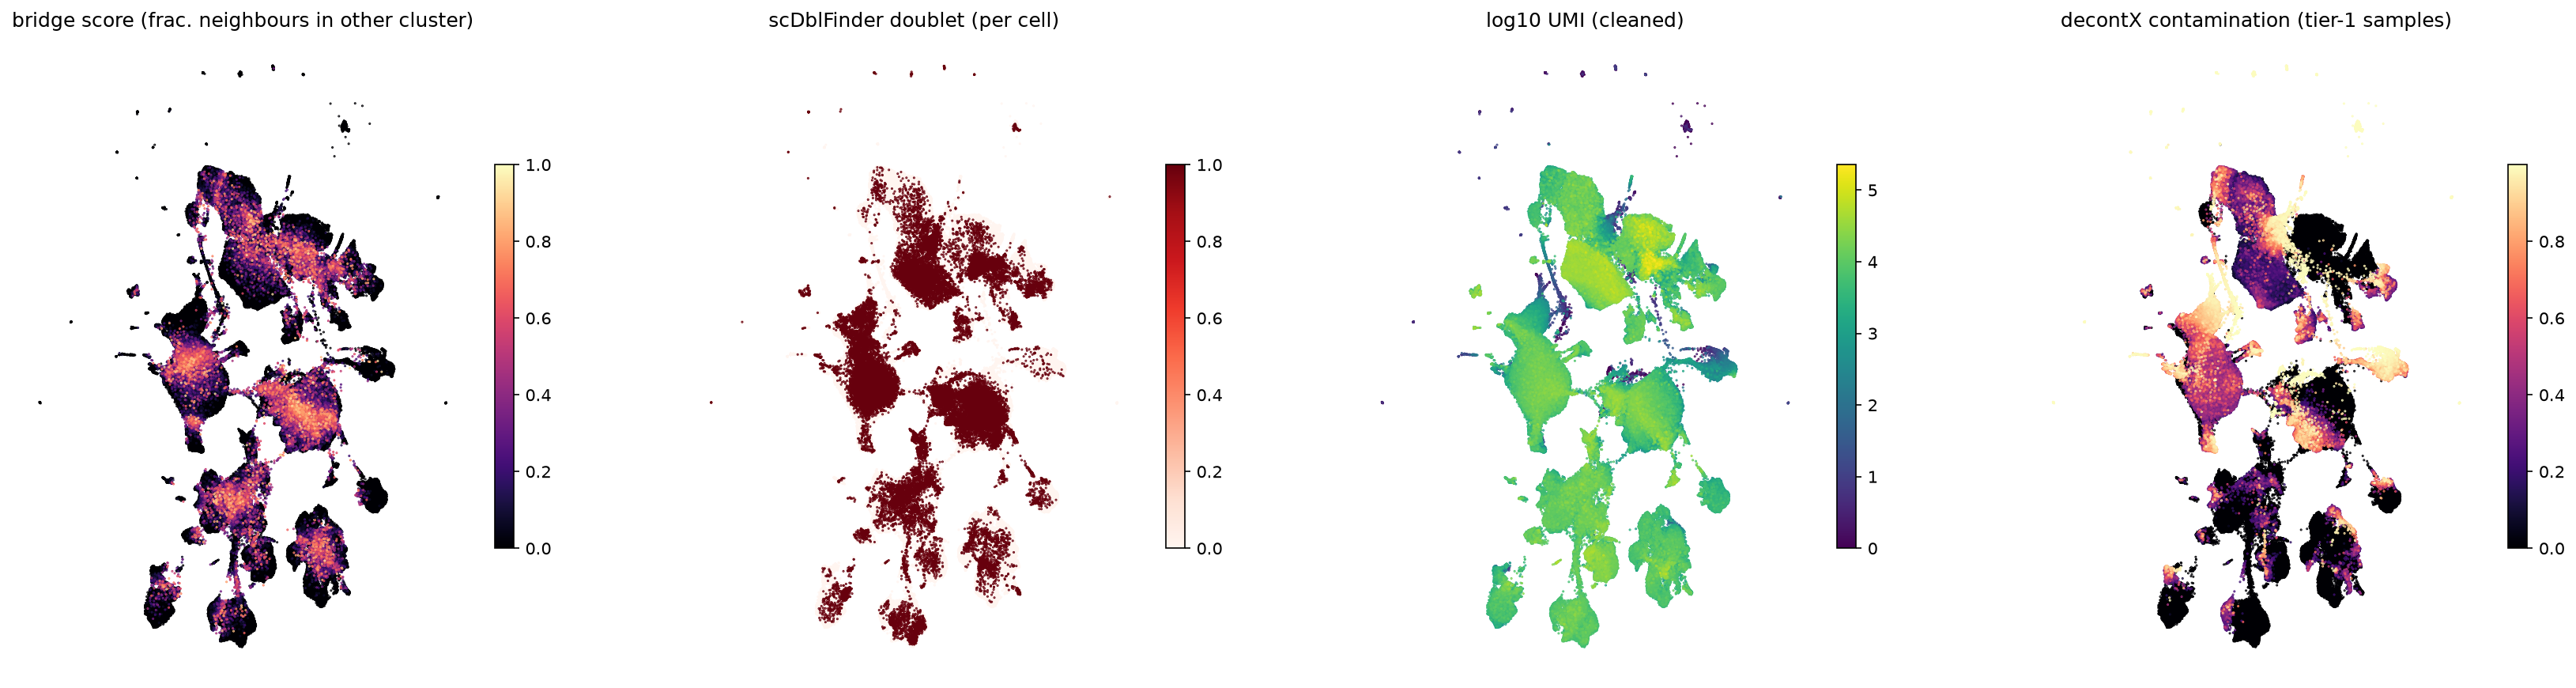

In [8]:
show("guilliams2022/08_totalvi_clean/streaks/umap_streak_drivers.png")

### 10 - strict QC

In [9]:
guard(30)
fresh("guilliams2022/10_strict")

free space on /mnt/masld_vault/cross_species_repro: 120 GB (needs 30)
output    guilliams2022/10_strict


In [10]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/10_strict_qc.py
"""Step 10 - strict QC approximating the authors' (user go 2026-11-12). Input: 07_clean (321,059) + 08 clean TotalVI latent.
Removed (all reasons recorded in obs strict_remove_reason, first reason wins in this order):
  1. scDblFinder_doublet  per-cell scDblFinder call (deviation from the MASLD consensus rule, to match the authors' strict
                          doublet removal: "eliminating these potential doublets", Cell 2022 p.382)
  2. dx_lt200             < 200 UMI after decontX (decontX samples, neutrophils exempt)
  3. bridge               > 50 % of the 15 nearest neighbours (clean TotalVI latent) carry another annotation_curated label
                          (intermediate profile between cell types; 'unresolved' neighbours count as different)
  4. sort_mismatch        cell type not expected for the sample's FACS gate (GEO sample titles, GSE192740 SOFT):
                          CD45+ -> immune + HsPCs; CD45- -> hepatocyte, endothelial, fibroblast, cholangiocyte (checked 2026-11-12: removed cells in CD45+ gates are Ptprc RNA 0-5 % positive vs 78-98 % in kept immune cells);
                          myeloid / monos+macs / DCs -> myeloid; hepatocytes -> hepatocyte; total live (CS144) and nuclei -> all.
                          'unresolved' cells are never removed for sort mismatch.
Writes <OUT>/10_strict/: guilliams2022_fig1b_strict.h5ad (kept cells; X = clean counts, layers counts = raw), cells_strict.parquet
(all 321,059 with reasons), per_sample_strict.tsv, removal_by_type.tsv, sample_sort_gate.tsv."""
import gzip
import os
import re

import anndata as ad
import numpy as np
import pandas as pd
from cuml.neighbors import NearestNeighbors

OUT = "/mnt/masld_vault/cross_species_repro/guilliams2022"
D = f"{OUT}/10_strict"
os.makedirs(D, exist_ok=True)

# sort gate per sample from GEO titles
title = {}
with gzip.open("/mnt/masld_vault/geo/GSE192740/_meta/family.soft.gz", "rt") as fh:
    gsm = None
    for line in fh:
        if line.startswith("^SAMPLE"):
            gsm = line.split("=")[1].strip()
        elif line.startswith("!Sample_title") and gsm:
            title[gsm] = line.split("=", 1)[1].strip()
st = pd.read_csv(f"{OUT}/01_raw/sample_table.tsv", sep="\t")
st["title"] = st.gsm.map(title)


def gate(t):
    t = t.lower()
    if "nuclei" in t:
        return "nuclei"
    if "hepatocytes" in t:
        return "hepatocytes"
    if re.search(r"cd45\+", t):
        return "CD45+"
    if re.search(r"cd45-", t):
        return "CD45-"
    if "myeloid" in t or "monos+macs" in t or re.search(r"(^|[^a-z])dcs([^a-z]|$)", t):
        return "myeloid"
    return "total_live"


st["gate"] = st.title.map(gate)
st[["sample", "gsm", "gate", "title"]].to_csv(f"{D}/sample_sort_gate.tsv", sep="\t", index=False)
print(st.gate.value_counts().to_string(), flush=True)
print(st[["sample", "gate", "title"]].to_string(index=False), flush=True)

IMMUNE = {"KC", "Monocyte", "T cell", "pDCs", "B cell", "cDC2", "cDC1", "ILC1", "Neutrophil", "NK cell", "Mig. cDCs",
          "Basophil", "HsPCs"}
MYELOID = {"KC", "Monocyte", "pDCs", "cDC2", "cDC1", "Neutrophil", "Mig. cDCs", "Basophil"}
NONIMM = {"Hepatocyte", "Endothelial", "Fibroblast", "Cholangiocyte"}
ALLOWED = {"CD45+": IMMUNE, "CD45-": NONIMM, "myeloid": MYELOID, "hepatocytes": {"Hepatocyte"}}

a = ad.read_h5ad(f"{OUT}/07_clean/guilliams2022_fig1b_clean.h5ad")
E = ad.read_h5ad(f"{OUT}/08_totalvi_clean/embeddings.h5ad")
assert (E.obs_names == a.obs_names).all()
o = a.obs
o["sort_gate"] = o["sample"].astype(str).map(st.set_index("sample").gate).values
lab = o["annotation_curated"].astype(str).values
Z = E.obsm["X_totalvi"].astype(np.float32)
_, idx = NearestNeighbors(n_neighbors=16).fit(Z).kneighbors(Z)
idx = np.asarray(idx)[:, 1:]
o["bridge_type"] = (lab[idx] != lab[:, None]).mean(1)
mism = np.array([g in ALLOWED and l != "unresolved" and l not in ALLOWED[g] for g, l in zip(o.sort_gate.values, lab)])
reason = np.full(len(o), "", dtype=object)
for name, m in [("scDblFinder_doublet", o.scDblFinder_doublet.values.astype(bool)), ("dx_lt200", o.dx_lt200.values.astype(bool)),
                ("bridge", o.bridge_type.values > 0.5), ("sort_mismatch", mism)]:
    reason[(reason == "") & m] = name
o["strict_remove_reason"] = pd.Categorical(np.where(reason == "", "kept", reason))
o["strict_keep"] = reason == ""
o[["sample", "sort_gate", "suspension", "annotation_curated", "bridge_type", "strict_remove_reason", "strict_keep"]].to_parquet(
    f"{D}/cells_strict.parquet")
print(o.strict_remove_reason.value_counts().to_string(), "\nkept", int(o.strict_keep.sum()), flush=True)
ps = pd.crosstab(o["sample"], o.strict_remove_reason)
ps.insert(0, "gate", st.set_index("sample").gate.reindex(ps.index).values)
ps.to_csv(f"{D}/per_sample_strict.tsv", sep="\t")
bt = pd.crosstab(o.annotation_curated, o.strict_remove_reason)
bt.to_csv(f"{D}/removal_by_type.tsv", sep="\t")
print(bt.to_string(), flush=True)
k = a[o.strict_keep.values].copy()
for c in k.obs.columns:
    if k.obs[c].dtype == object:
        k.obs[c] = k.obs[c].astype(str)
k.uns["note"] = ("STRICT 2026-11-12: 07_clean minus per-cell scDblFinder doublets, <200 UMI after decontX, bridge cells (>50 % of 15 NN "
                 "with another curated label), sort-gate mismatches (GEO titles). See 10_strict/cells_strict.parquet.")
k.write_h5ad(f"{D}/guilliams2022_fig1b_strict.h5ad", compression="gzip")
print("written", k.shape, flush=True)

Writing /home/ubuntu/liver_cross_species/notebooks/work/10_strict_qc.py


In [11]:
run("10_strict_qc.py", "rapids-sc", gpu=0)

sort_mismatch           39843
scDblFinder_doublet     35042
dx_lt200                 8522
bridge                   3100
kept 234552
strict_remove_reason  bridge  dx_lt200   kept  scDblFinder_doublet  sort_mismatch
annotation_curated
B cell                    15        54   8951                  624            203
Basophil                  52         2    257                  296             71
Cholangiocyte             26        25   2519                  261             50
Endothelial              153      1299  51200                 8711          17468
Fibroblast               114       290   3060                  894           2001
Hepatocyte               692      5829  44873                 8478          18486
ILC1                     155        64   4878                  239             80
KC                       488       802  48374                 8168            451
Mig. cDCs                 33         1    851                  167             12
Monocyte                 372 

In [12]:
compare_tsv("guilliams2022/10_strict/per_sample_strict.tsv")
compare_tsv("guilliams2022/10_strict/removal_by_type.tsv")

guilliams2022/10_strict/per_sample_strict.tsv: shape record (46, 6) / repro (46, 6); max numeric diff 0; text columns identical: True
guilliams2022/10_strict/removal_by_type.tsv: shape record (17, 5) / repro (17, 5); max numeric diff 0; text columns identical: True


np.True_